# Ablation of embedding dimension on fine-grained bio metrics

In [133]:
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ortho_group

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

In [2]:
import os
import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/')
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

In [3]:
import scib
from scib.metrics import *
from analysis_helpers import *

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## AGREE and RKNN

Are your k-nearest neighbors the same when you embed in different PCA dimensions?

In [34]:
from sklearn.neighbors import NearestNeighbors

In [228]:
adata = sc.read('../data/mouse_retina.h5ad')

In [ ]:
sc.pl.umap(adata, color=['CellType', 'dataset'])

In [57]:
adata.obs['CellType'].value_counts()

CellType
bipolar                 29779
rods                    29491
amacrine                 4678
muller                   4569
cones                    1916
ganglion                  432
vascular_endothelium      252
horizontal                252
fibroblasts                85
microglia                  67
pericytes                  63
astrocytes                 54
Name: count, dtype: int64

In [151]:
sub = adata[adata.obs['dataset'] == 'BM'].copy()
sc.pp.highly_variable_genes(sub, flavor='seurat_v3', layer='counts', n_top_genes=2000)

X1 = sc.tl.pca(sub[:, sub.var.highly_variable].X, n_comps=8)
X2 = sc.tl.pca(sub[:, sub.var.highly_variable].X, n_comps=9)

nn = NearestNeighbors(n_neighbors=51).fit(X1)
distances1, indices1 = nn.kneighbors(X1)
indices1 = indices1[:, 1:]
nn = NearestNeighbors(n_neighbors=51).fit(X2)
distances2, indices2 = nn.kneighbors(X2)
indices2 = indices2[:, 1:]

overlap_counts = np.zeros(indices1.shape[0])

for i in range(indices1.shape[0]):
    intersection = np.intersect1d(indices1[i], indices2[i], assume_unique=True)
    overlap_counts[i] = len(intersection)

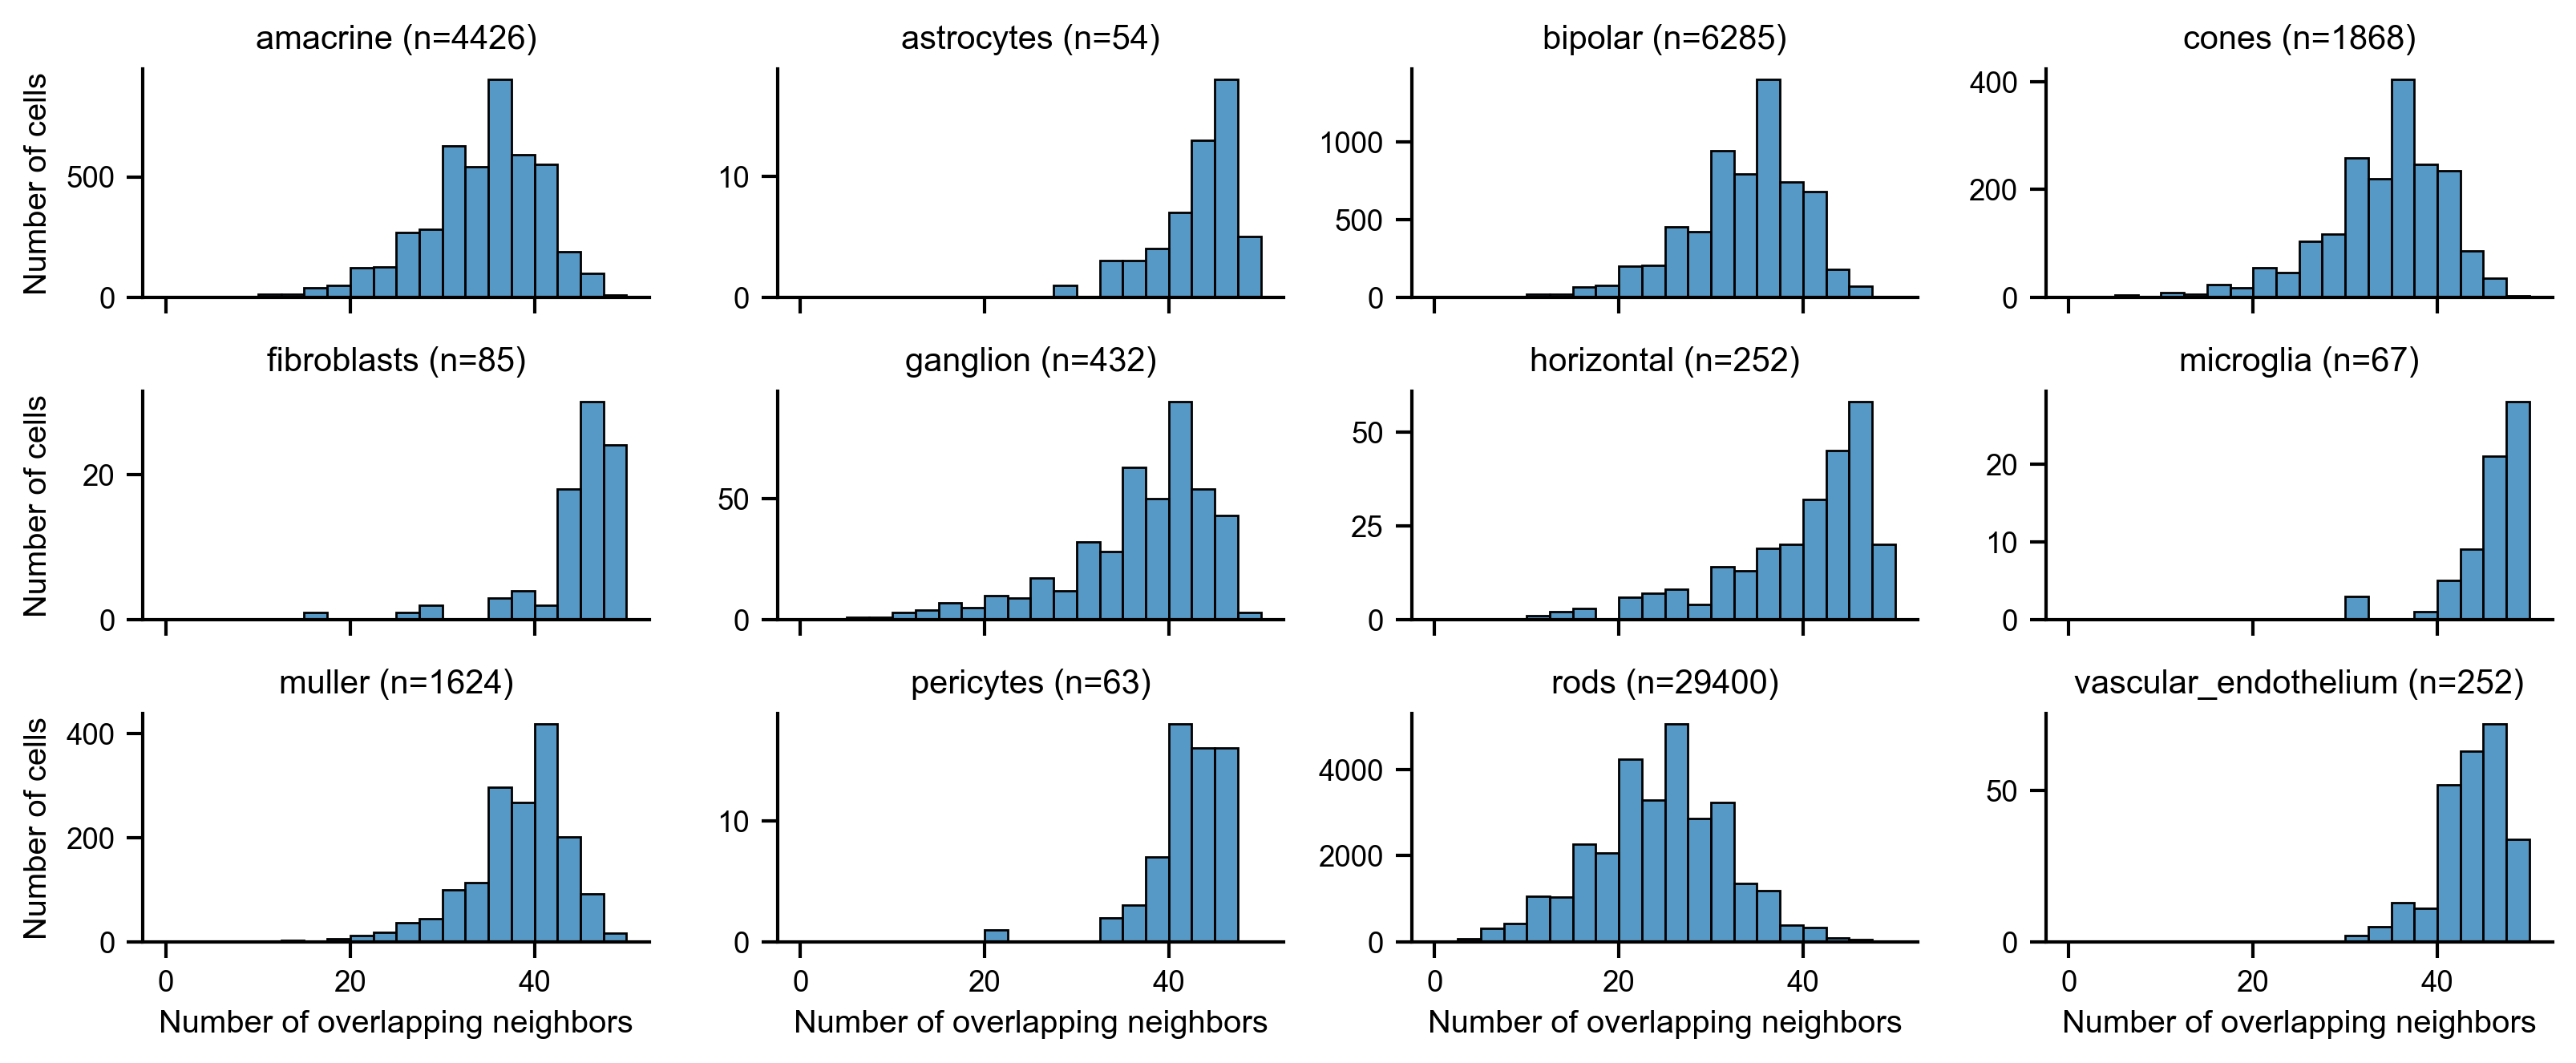

In [152]:
counts = sub.obs['CellType'].value_counts()
cell_type_mapping = {label: f"{label} (n={counts[label]})" for label in counts.index}
sub.obs['CellType_with_n'] = sub.obs['CellType'].map(cell_type_mapping)


sub.obs['knn_overlap'] = overlap_counts
with plt.rc_context({'figure.dpi': 300}):
    sns.set_context("paper", font_scale=1)
    g = sns.displot(
        data=sub.obs, 
        x='knn_overlap', 
        col='CellType_with_n',
        col_wrap=4,
        kind='hist', 
        bins=20, 
        common_bins=True, 
        height=1.5, 
        aspect=1.8,
        facet_kws={'sharey': False}
    )
    g.set_axis_labels("Number of overlapping neighbors", "Number of cells")
    g.set_titles(col_template="{col_name}", size=10)
    g.figure.align_labels()
    plt.show()

In [107]:
sub.obs.groupby('CellType')['knn_overlap'].median()

/scratch-ssd/slurm-jobs/yinian/1778040/ipykernel_2893984/2221798901.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sub.obs.groupby('CellType')['knn_overlap'].median()


CellType
amacrine                35.0
astrocytes              44.0
bipolar                 34.0
cones                   35.0
fibroblasts             46.0
ganglion                38.0
horizontal              42.0
microglia               47.0
muller                  39.0
pericytes               43.0
rods                    24.0
vascular_endothelium    44.0
Name: knn_overlap, dtype: float64

Instead of modifying the number of PCs, modify the highly variable gene selection method.

In [142]:
sub = adata[adata.obs['dataset'] == 'BM'].copy()
sc.pp.highly_variable_genes(sub, flavor='seurat_v3', layer='counts', n_top_genes=2000)
sub.var['seurat_hvg'] = sub.var['highly_variable']
sc.pp.highly_variable_genes(sub, n_top_genes=2000)

X1 = sc.tl.pca(sub[:, sub.var.seurat_hvg].X, n_comps=8)
X2 = sc.tl.pca(sub[:, sub.var.highly_variable].X, n_comps=8)

nn = NearestNeighbors(n_neighbors=51).fit(X1)
distances1, indices1 = nn.kneighbors(X1)
indices1 = indices1[:, 1:]
nn = NearestNeighbors(n_neighbors=51).fit(X2)
distances2, indices2 = nn.kneighbors(X2)
indices2 = indices2[:, 1:]

overlap_counts = np.zeros(indices1.shape[0])

for i in range(indices1.shape[0]):
    intersection = np.intersect1d(indices1[i], indices2[i], assume_unique=True)
    overlap_counts[i] = len(intersection)

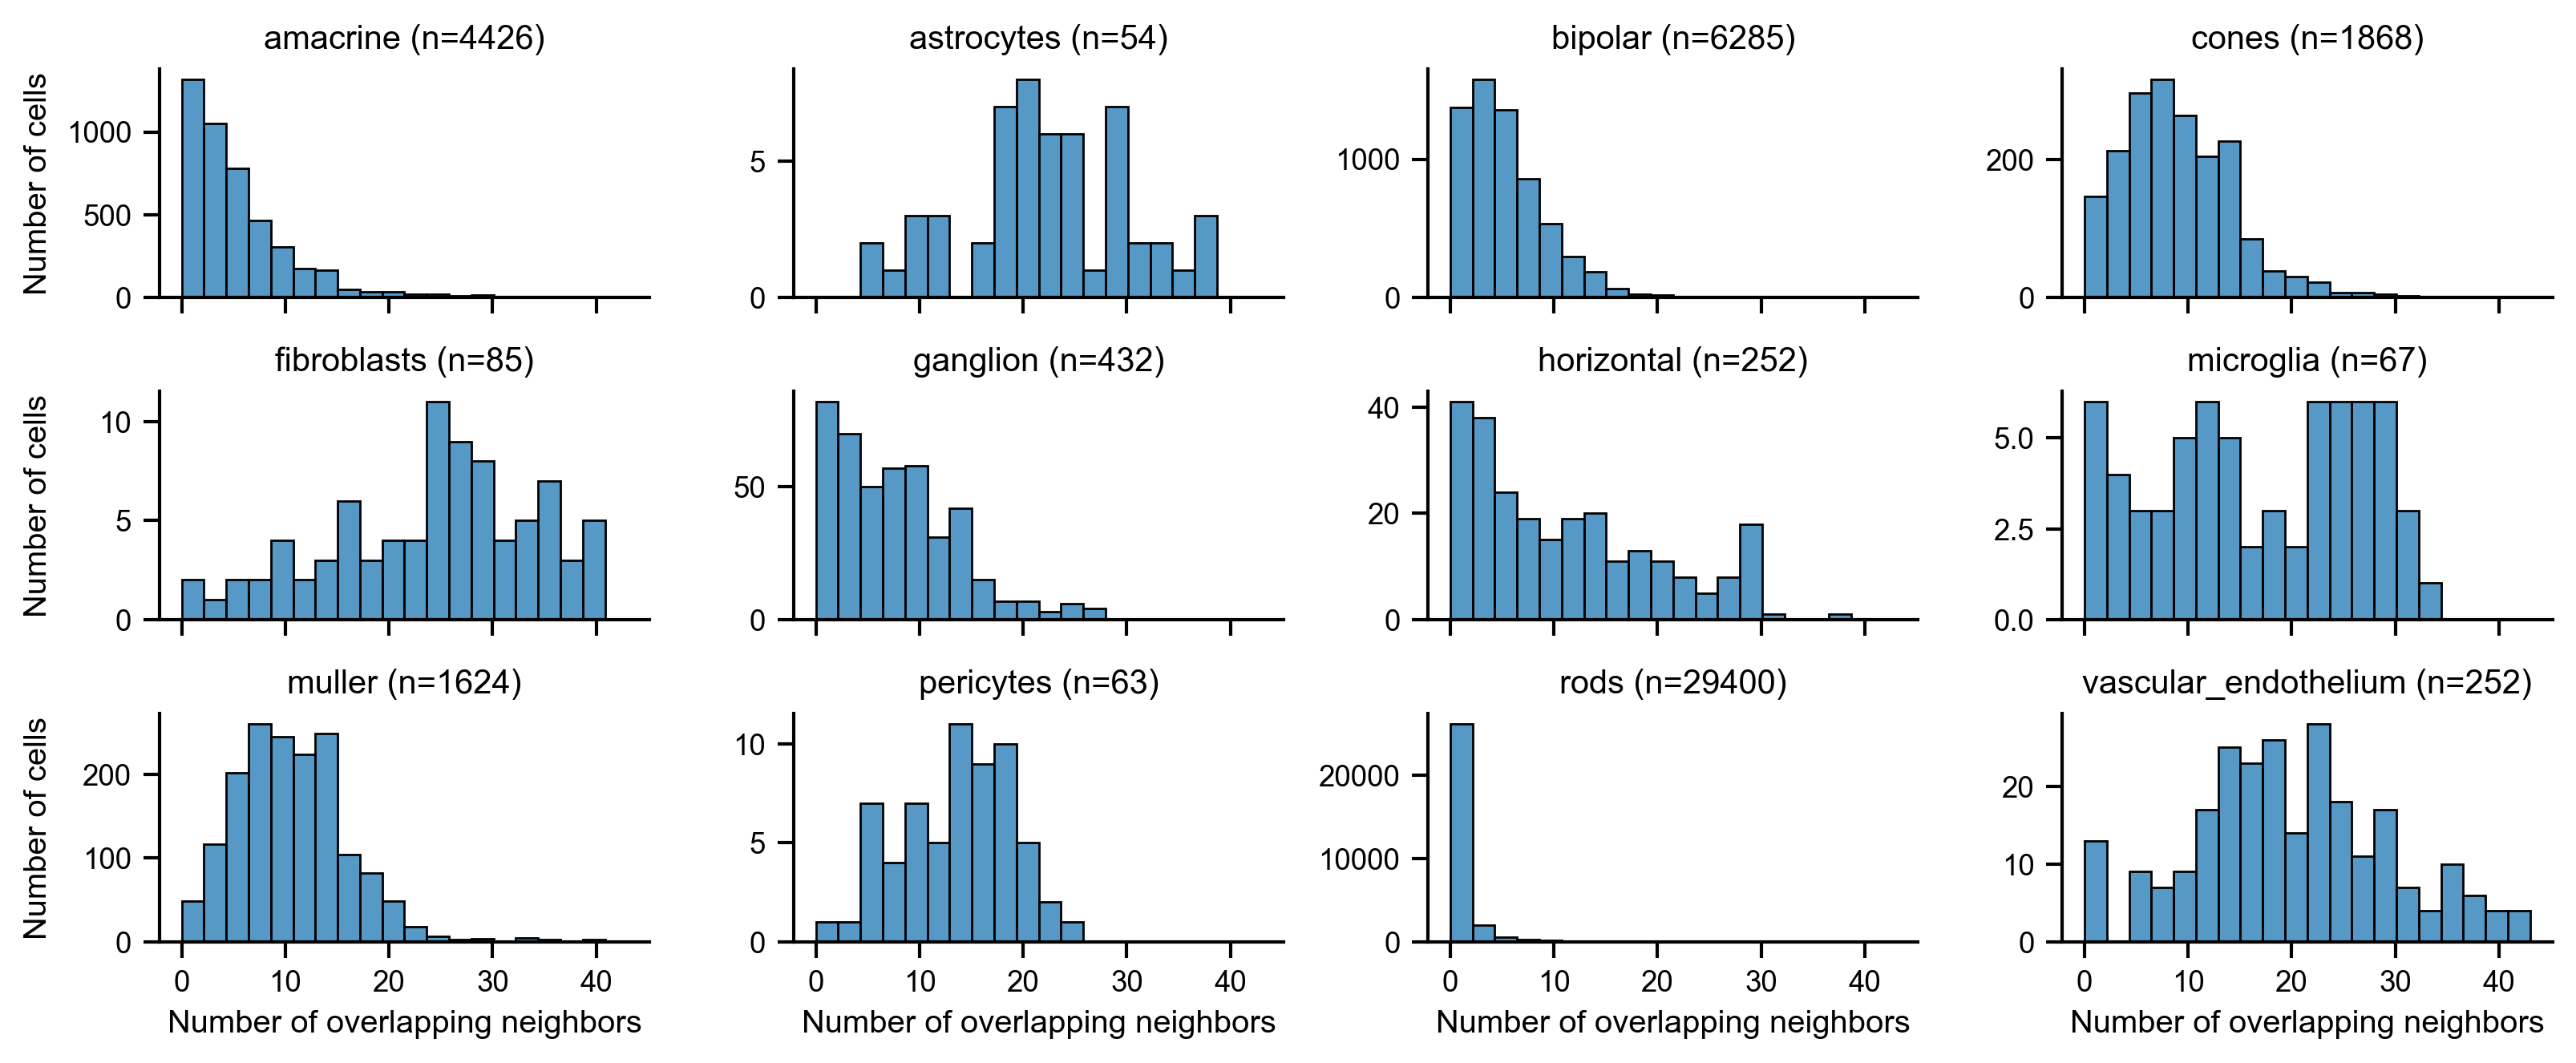

In [150]:
counts = sub.obs['CellType'].value_counts()
cell_type_mapping = {label: f"{label} (n={counts[label]})" for label in counts.index}
sub.obs['CellType_with_n'] = sub.obs['CellType'].map(cell_type_mapping)


sub.obs['knn_overlap'] = overlap_counts
with plt.rc_context({'figure.dpi': 300}):
    sns.set_context("paper", font_scale=1)
    g = sns.displot(
        data=sub.obs, 
        x='knn_overlap', 
        col='CellType_with_n',
        col_wrap=4,
        kind='hist', 
        bins=20, 
        common_bins=True, 
        height=1.5, 
        aspect=1.8,
        facet_kws={'sharey': False}
    )
    g.set_axis_labels("Number of overlapping neighbors", "Number of cells")

    g.set_titles(col_template="{col_name}", size=10)
    g.figure.align_labels()
    plt.show()

In [144]:
sub.obsm['X1'] = X1
sub.obsm['X2'] = X2

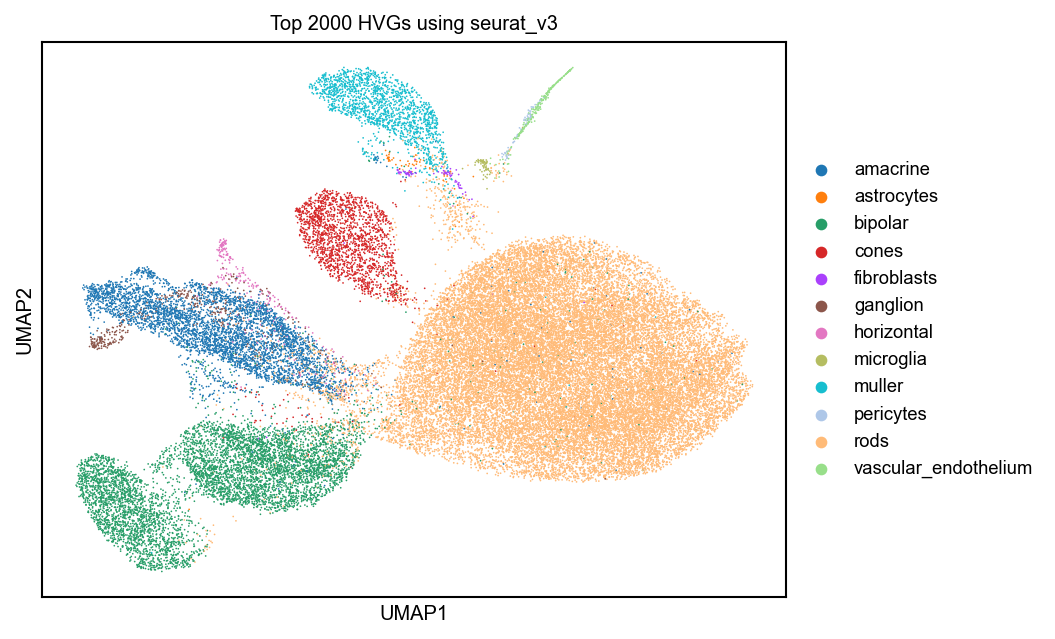

In [145]:
sc.pp.neighbors(sub, use_rep="X1")
sc.tl.umap(sub)
with plt.rc_context({'figure.dpi': 150}):
    sc.pl.umap(sub, color='CellType', title='Top 2000 HVGs using seurat_v3')

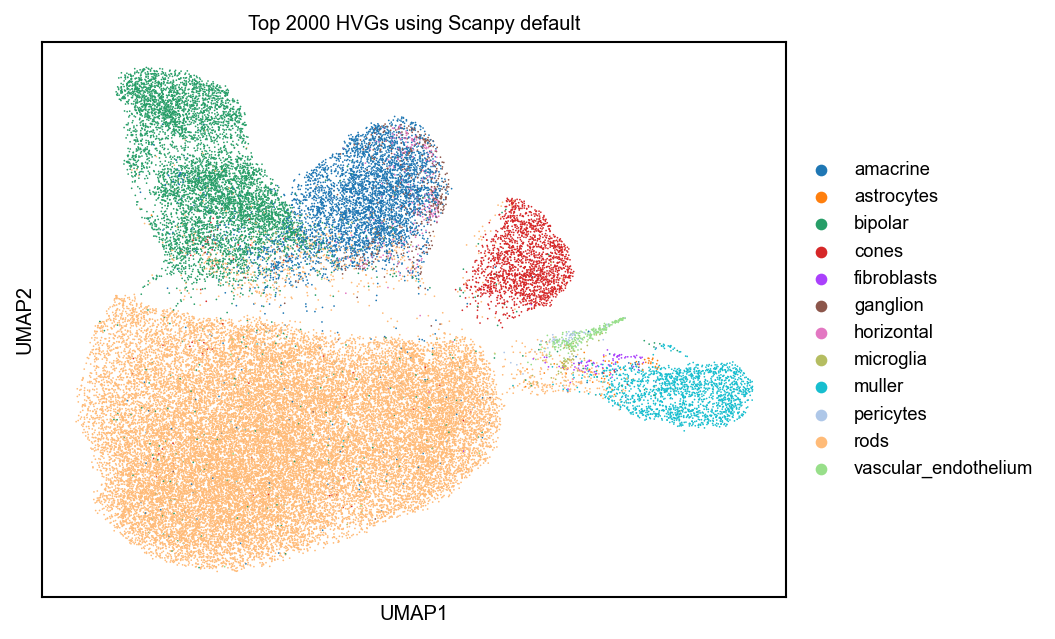

In [146]:
sc.pp.neighbors(sub, use_rep="X2")
sc.tl.umap(sub)
with plt.rc_context({'figure.dpi': 150}):

    sc.pl.umap(sub, color='CellType', title='Top 2000 HVGs using Scanpy default')

In [110]:
sub.obs.groupby('CellType')['knn_overlap'].median()

/scratch-ssd/slurm-jobs/yinian/1778040/ipykernel_2893984/2221798901.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sub.obs.groupby('CellType')['knn_overlap'].median()


CellType
amacrine                 5.0
astrocytes              19.0
bipolar                  5.0
cones                    7.0
fibroblasts             27.0
ganglion                 7.0
horizontal               8.0
microglia               16.0
muller                  10.0
pericytes               15.0
rods                     0.0
vascular_endothelium    19.0
Name: knn_overlap, dtype: float64

Repeat for NeurIPS BMMC data

In [153]:
adata = sc.read('../data/neurips_bmmc.h5ad')

In [ ]:
sc.pl.umap(adata, color=['cell_type', 'batch'])

In [156]:
sub = adata[adata.obs['batch'] == 's3d7'].copy()
sc.pp.highly_variable_genes(sub, flavor='seurat_v3', layer='counts', n_top_genes=2000)

X1 = sc.tl.pca(sub[:, sub.var.highly_variable].X, n_comps=8)
X2 = sc.tl.pca(sub[:, sub.var.highly_variable].X, n_comps=9)

nn = NearestNeighbors(n_neighbors=51).fit(X1)
distances1, indices1 = nn.kneighbors(X1)
indices1 = indices1[:, 1:]
nn = NearestNeighbors(n_neighbors=51).fit(X2)
distances2, indices2 = nn.kneighbors(X2)
indices2 = indices2[:, 1:]

overlap_counts = np.zeros(indices1.shape[0])

for i in range(indices1.shape[0]):
    intersection = np.intersect1d(indices1[i], indices2[i], assume_unique=True)
    overlap_counts[i] = len(intersection)

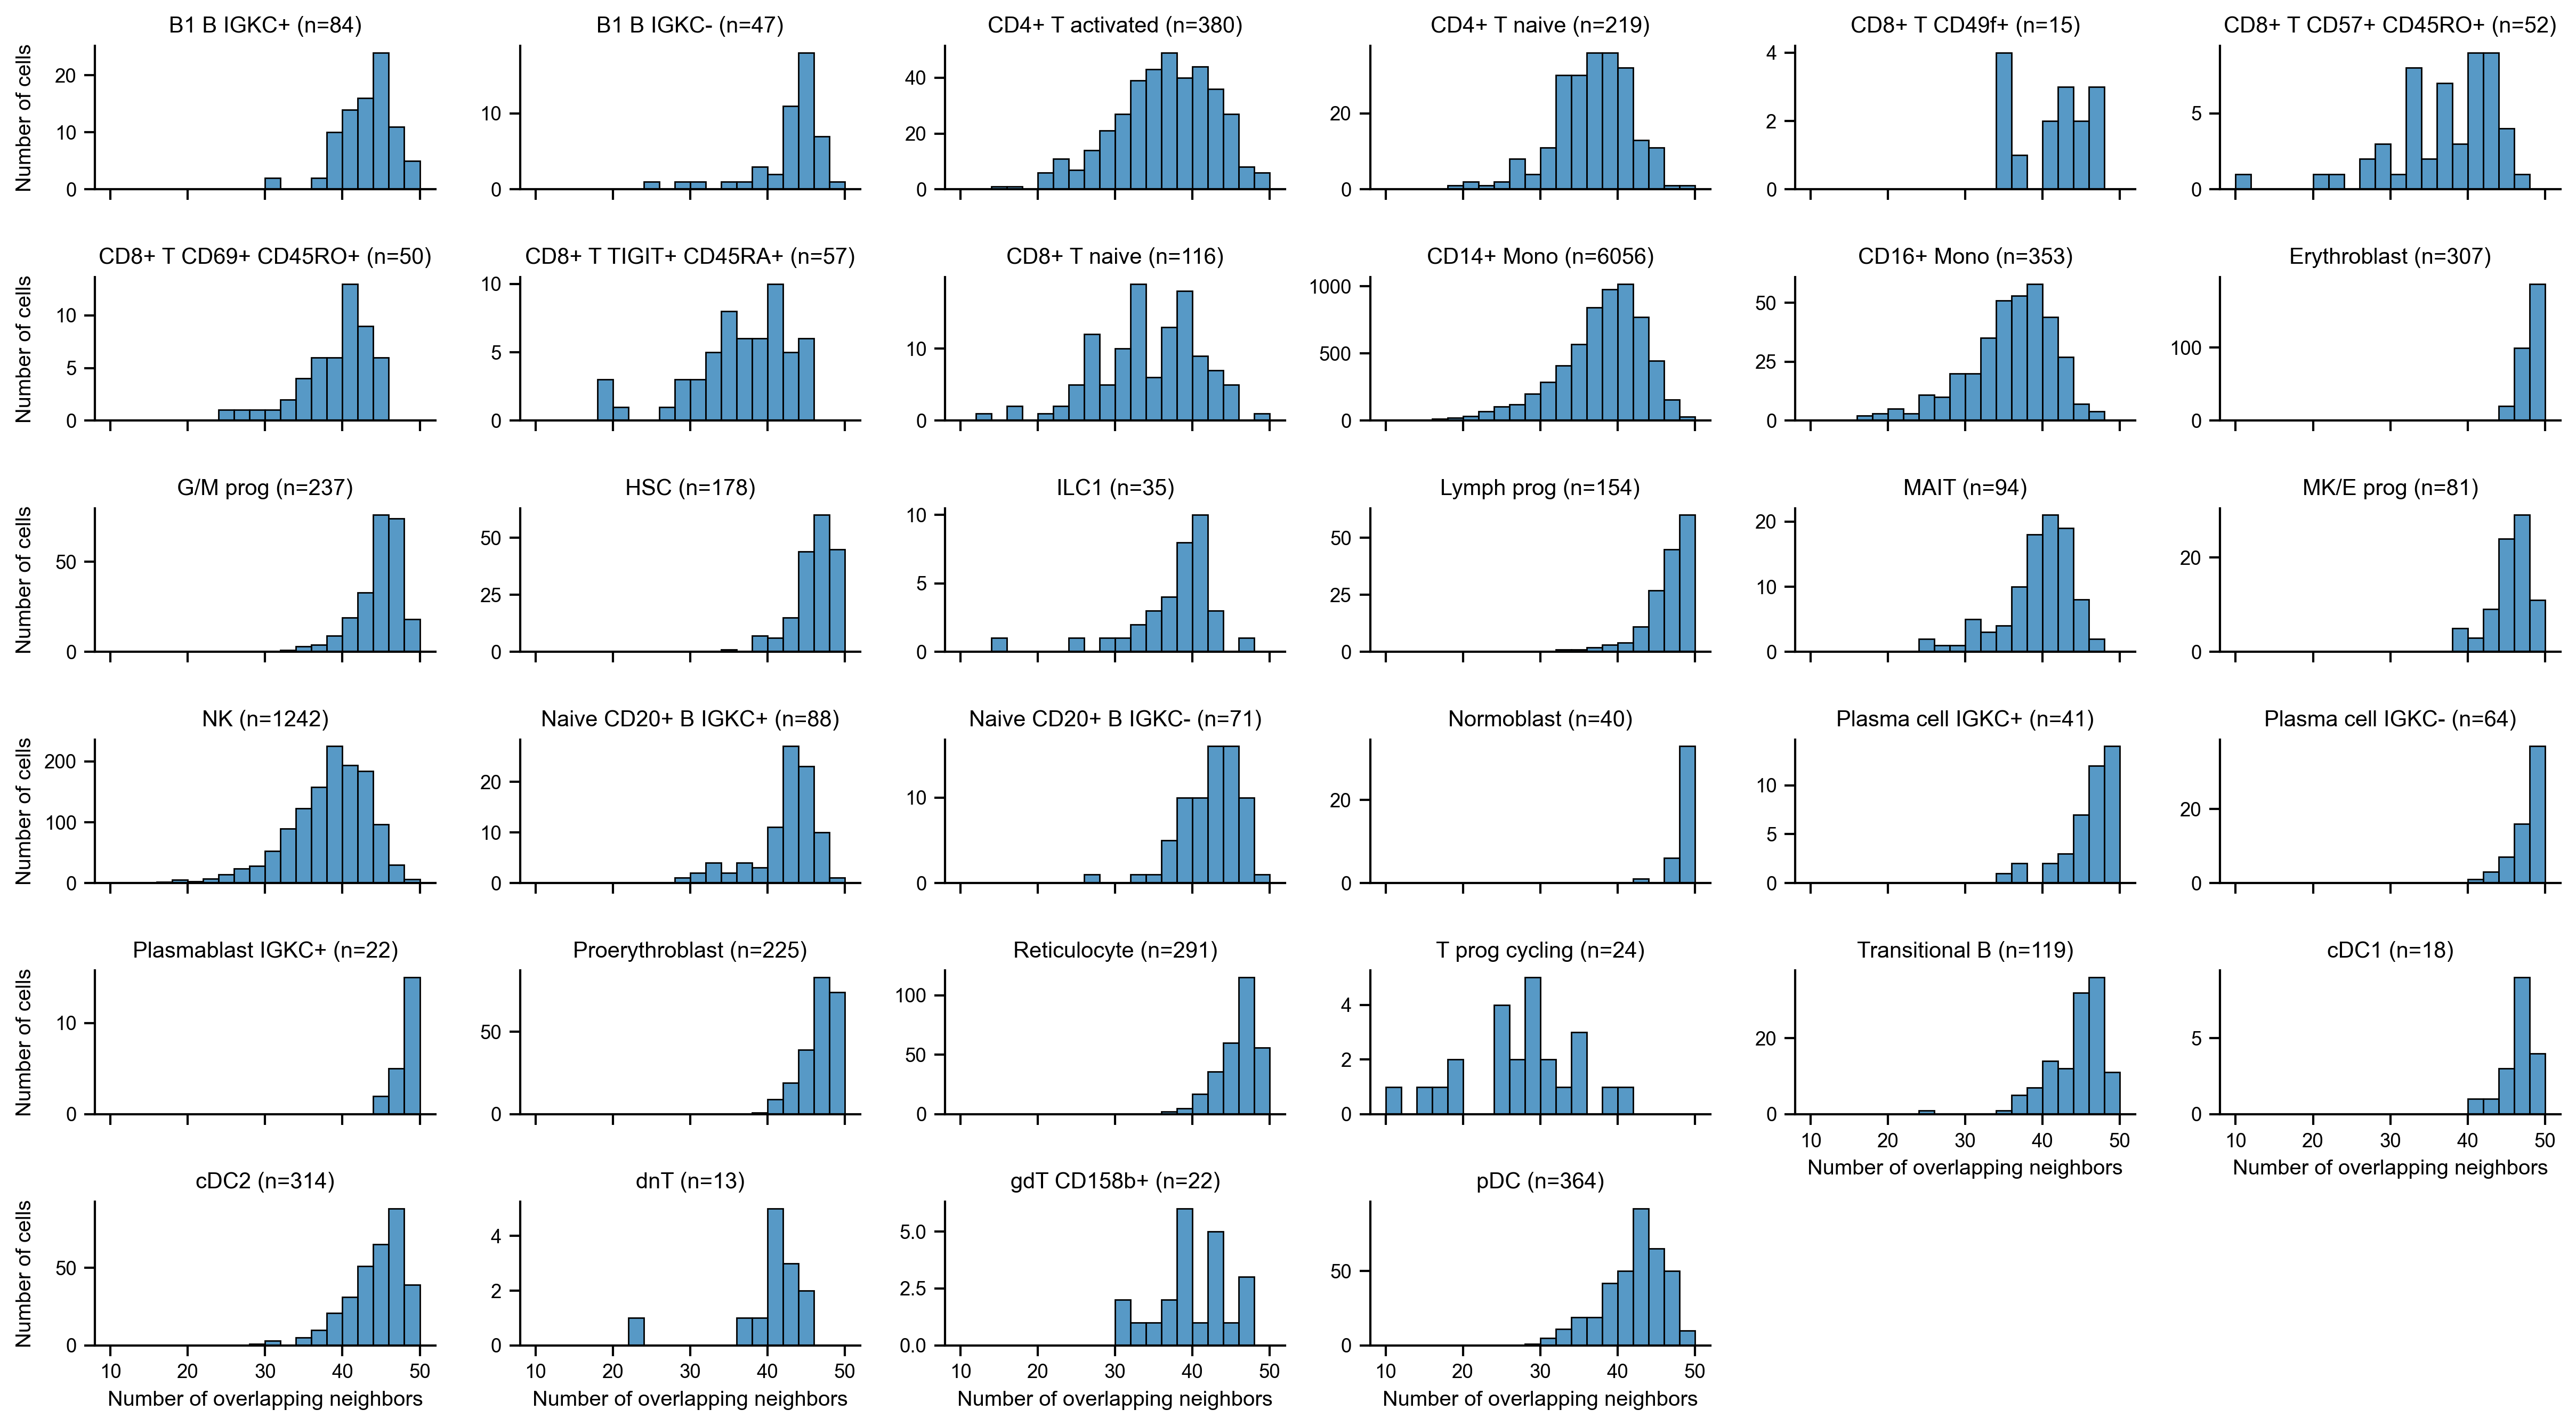

In [158]:
counts = sub.obs['cell_type'].value_counts()
cell_type_mapping = {label: f"{label} (n={counts[label]})" for label in counts.index}
sub.obs['CellType_with_n'] = sub.obs['cell_type'].map(cell_type_mapping)


sub.obs['knn_overlap'] = overlap_counts
with plt.rc_context({'figure.dpi': 300}):
    sns.set_context("paper", font_scale=1)
    g = sns.displot(
        data=sub.obs, 
        x='knn_overlap', 
        col='CellType_with_n',
        col_wrap=6,
        kind='hist', 
        bins=20, 
        common_bins=True, 
        height=1.5, 
        aspect=1.8,
        facet_kws={'sharey': False}
    )
    g.set_axis_labels("Number of overlapping neighbors", "Number of cells")
    g.set_titles(col_template="{col_name}", size=10)
    g.figure.align_labels()
    plt.show()

## Investigate CORRMSE

In [ ]:
adata.obsm['X_pca_8'] = sc.tl.pca(adata[:, adata.var.highly_variable].X, n_comps=8)
adata.obsm['X_pca_9'] = sc.tl.pca(adata[: ,adata.var.highly_variable].X, n_comps=9)

In [230]:
def chunked_corr_mse(X1, X2, chunk_size=5000):
    # 1. Standardize rows (mean=0, std=1) for correlation calculation
    def standardize(X):
        return (X - X.mean(axis=1, keepdims=True)) / X.std(axis=1, ddof=1, keepdims=True)

    Z1, Z2 = standardize(X1), standardize(X2)
    n_features = Z1.shape[0]
    total_sq_diff = 0.0

    # 2. Compute MSE in blocks to save RAM
    for i in range(0, n_features, chunk_size):
        end_i = min(i + chunk_size, n_features)
        # Calculate rows i to end_i for both matrices
        row_chunk1 = np.dot(Z1[i:end_i], Z1.T) / (Z1.shape[1] - 1)
        row_chunk2 = np.dot(Z2[i:end_i], Z2.T) / (Z2.shape[1] - 1)
        
        total_sq_diff += np.sum((row_chunk1 - row_chunk2)**2)

    return total_sq_diff / (n_features**2)

In [231]:
sub = adata[(adata.obs['dataset'] == 'BM') & (adata.obs['CellType'] == 'rods')]

In [169]:
chunked_corr_mse(sub.obsm['X_pca_8'], sub.obsm['X_pca_9'])

np.float32(0.0022018556)

In [236]:
corr1 = np.corrcoef(sub.obsm['X_pca_8'])
corr1.mean()

np.float64(0.6416748123846655)

In [237]:
sub = adata[(adata.obs['dataset'] == 'BM') & (adata.obs['CellType'] == 'bipolar')]

In [239]:
corr1 = np.corrcoef(sub.obsm['X_pca_8'])
corr1.mean()

np.float64(0.28125282581604116)

## Investigate MORANI

Which genes are selected by Moran's I and are they valid?

In [182]:
adata = sc.read('../data/tabula_muris_lung.h5ad')

In [183]:
res = scib.metrics.sub_variable_genes(adata, 'cell_ontology_id', 'mouse.id', 500, 0.7)

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/morans_i.py:142: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = adata.obs.groupby([label_key, batch_key]).size()


571 5054
1758 4760
507 3215


In [191]:
res

[{'cell_ontology_id': 'CL:0000499',
  'mouse.id': '3-M-5/6',
  'genes': Dcn         0.896734
  Serpinf1    0.890773
  Aspn        0.853561
  Ly6a        0.885474
  Pi16        0.858775
  Malat1      0.903877
  Inmt        0.901545
  Hhip        0.904687
  Name: morans_i, dtype: float64},
 {'cell_ontology_id': 'CL:0000499',
  'mouse.id': '3-M-7/8',
  'genes': Dcn         0.865834
  Lum         0.852672
  Ndufa4l2    0.903824
  Serpinf1    0.875256
  Ccl11       0.852968
  Igfbp4      0.861433
  Aspn        0.880281
  Mustn1      0.881670
  Scara5      0.857540
  Enpp2       0.862658
  Ly6a        0.911036
  Pi16        0.906940
  Malat1      0.908631
  Gsn         0.869200
  Gucy1b3     0.864998
  Npnt        0.861078
  Macf1       0.868935
  Limch1      0.861647
  Inmt        0.936869
  Mgp         0.851839
  Hhip        0.939730
  Clec3b      0.851246
  Name: morans_i, dtype: float64},
 {'cell_ontology_id': 'CL:0000623',
  'mouse.id': '3-M-7/8',
  'genes': Series([], Name: morans_i, d

In [188]:
res[1]['genes'].index

Index(['Dcn', 'Lum', 'Ndufa4l2', 'Serpinf1', 'Ccl11', 'Igfbp4', 'Aspn',
       'Mustn1', 'Scara5', 'Enpp2', 'Ly6a', 'Pi16', 'Malat1', 'Gsn', 'Gucy1b3',
       'Npnt', 'Macf1', 'Limch1', 'Inmt', 'Mgp', 'Hhip', 'Clec3b'],
      dtype='object')

In [186]:
adata.obs['total_counts'] = adata.layers['counts'].sum(1)

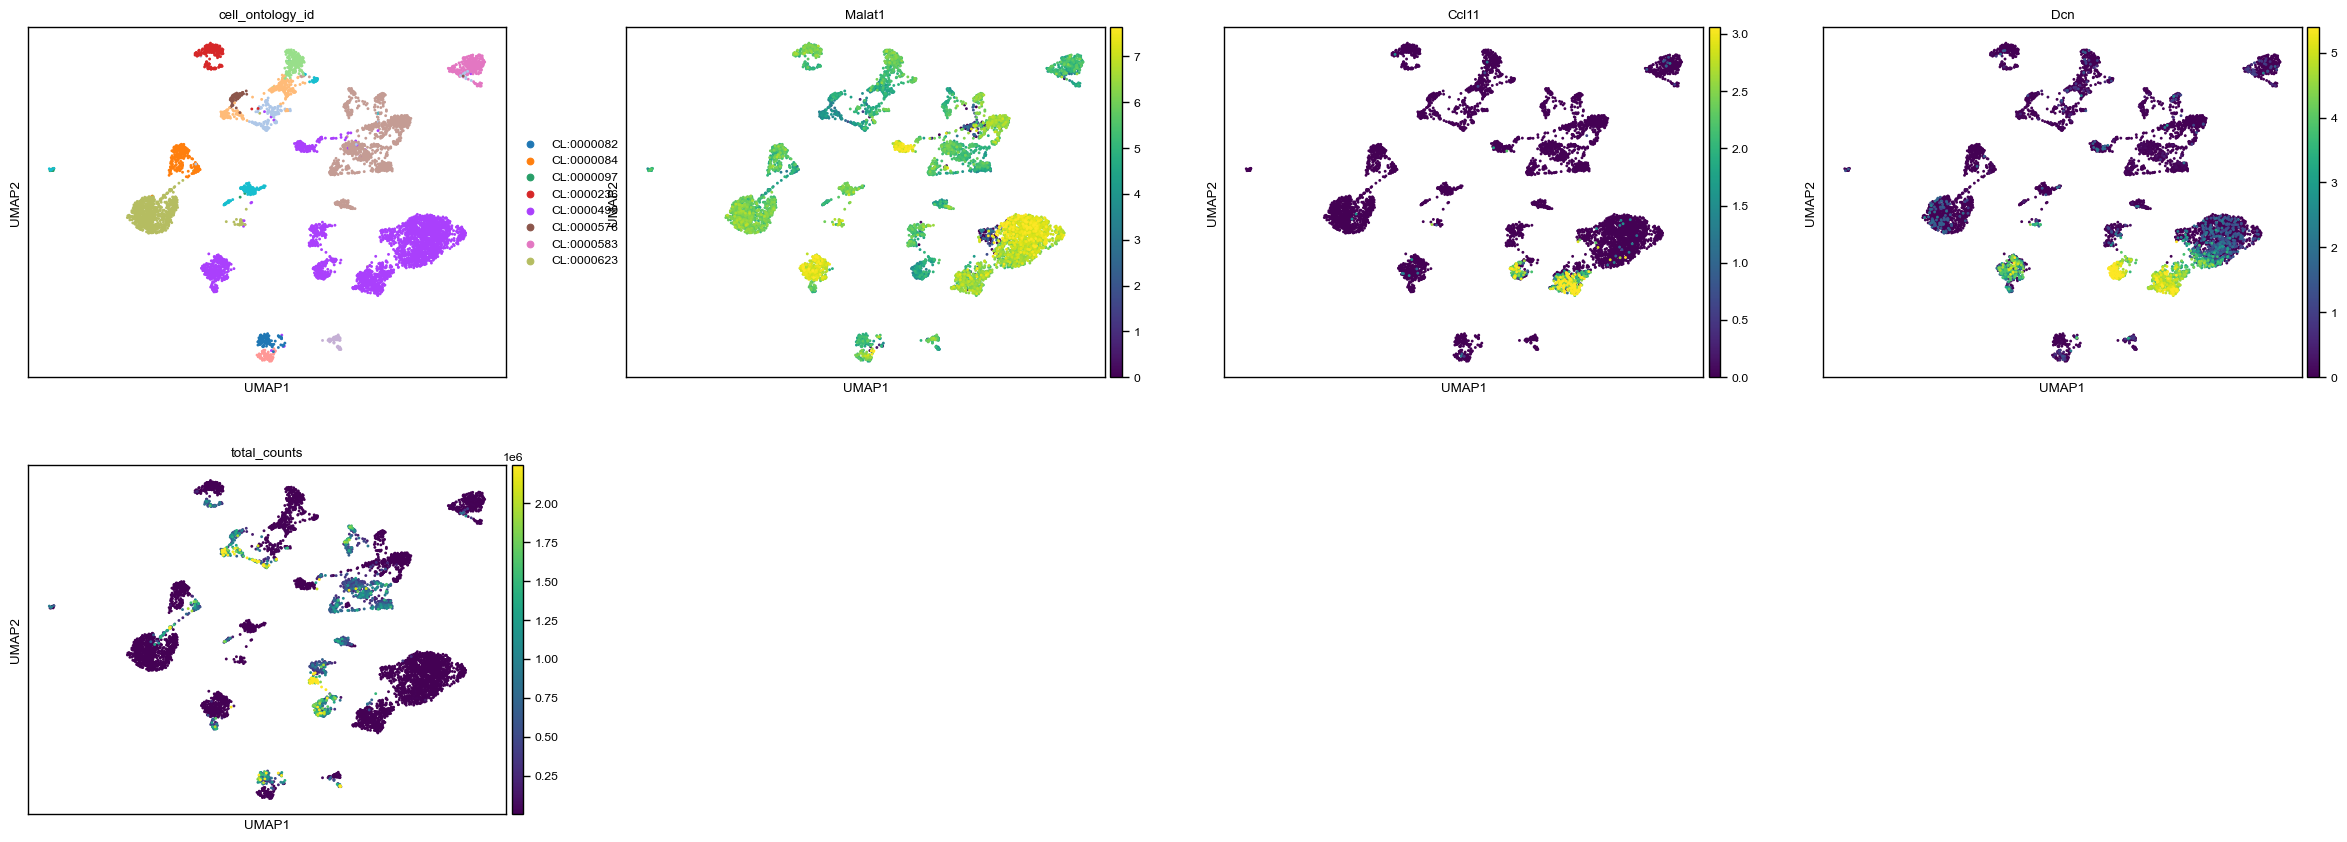

In [196]:
sc.pl.umap(adata, color=['cell_ontology_id', 'Malat1', 'Ccl11', 'Dcn', 'total_counts'], vmax='p99')

/scratch-ssd/slurm-jobs/yinian/1778040/ipykernel_2893984/3621866885.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=plot_df, x='Gene Group', y='Average Expression', palette='Set2')
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


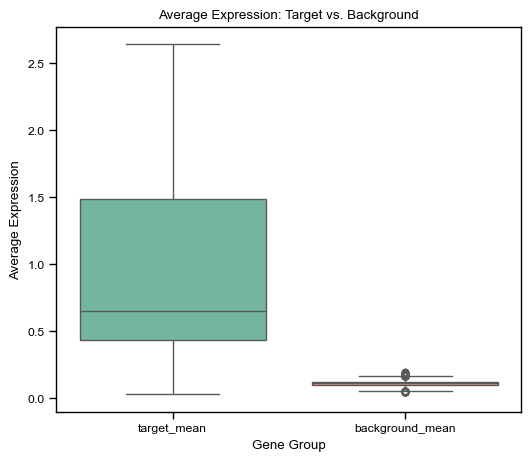

In [190]:
target_genes = res[1]['genes'].index
background_genes = [g for g in adata.var_names if g not in target_genes]

adata.obs['target_mean'] = adata[:, target_genes].X.mean(axis=1)
adata.obs['background_mean'] = adata[:, background_genes].X.mean(axis=1)

plot_df = adata.obs[['target_mean', 'background_mean']].melt(
    var_name='Gene Group', 
    value_name='Average Expression'
)

plt.figure(figsize=(6, 5))
sns.boxplot(data=plot_df, x='Gene Group', y='Average Expression', palette='Set2')
plt.title('Average Expression: Target vs. Background')
plt.show()

In [192]:
adata.var['mean_expression'] = adata.X.mean(axis=0).A1

In [193]:
adata.var['expression_rank'] = adata.var['mean_expression'].rank(ascending=False, method='min')

In [194]:
target_rankings = adata.var.loc[adata.var.index.isin(target_genes), ['mean_expression', 'expression_rank']]
target_rankings = target_rankings.sort_values('expression_rank')

print(target_rankings)

          mean_expression  expression_rank
Malat1           5.537783              1.0
Mgp              2.712039             26.0
Gsn              2.510467             52.0
Inmt             1.616746            148.0
Macf1            1.080615            305.0
Ly6a             1.076064            309.0
Clec3b           0.833373            494.0
Igfbp4           0.758790            572.0
Limch1           0.738467            589.0
Dcn              0.727167            608.0
Npnt             0.567141            900.0
Mustn1           0.357423           1707.0
Hhip             0.320444           1956.0
Pi16             0.312454           2033.0
Enpp2            0.296213           2180.0
Lum              0.273749           2404.0
Serpinf1         0.237309           2791.0
Aspn             0.197713           3444.0
Ccl11            0.139129           4821.0
Gucy1b3          0.132221           5038.0
Ndufa4l2         0.127203           5214.0
Scara5           0.125591           5265.0


In [212]:
adata = sc.read('../data/cellranger_versions.h5ad')

In [219]:
res = scib.metrics.sub_variable_genes(adata[:, adata.var.highly_variable], 'cell_type', 'batch', 100, 0.7)

/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/scib/metrics/morans_i.py:142: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = adata.obs.groupby([label_key, batch_key]).size()


2846 1166
2846 1769
544 1275
544 1864
164 1583
164 2170
386 962
386 1867
468 1017
468 1904
1176 923
1176 1804
439 979
439 1815
376 832
376 1754
1429 693
1429 1620
1238 797
1238 1727
324 861
324 1725
108 1483
108 2158


In [220]:
res

[{'cell_type': 'CD14 monocyte',
  'batch': 'v6',
  'genes': HLA-DRA     0.850403
  HLA-DPA1    0.851355
  Name: morans_i, dtype: float64},
 {'cell_type': 'CD14 monocyte',
  'batch': 'v8',
  'genes': Series([], Name: morans_i, dtype: float64)},
 {'cell_type': 'CD16 monocyte',
  'batch': 'v6',
  'genes': CDKN1C    0.858194
  Name: morans_i, dtype: float64},
 {'cell_type': 'CD16 monocyte',
  'batch': 'v8',
  'genes': Series([], Name: morans_i, dtype: float64)},
 {'cell_type': 'DC',
  'batch': 'v6',
  'genes': VCAN        0.902250
  CD14        0.854151
  HLA-DRA     0.852512
  HLA-DPA1    0.858238
  HLA-DPB1    0.865460
  Name: morans_i, dtype: float64},
 {'cell_type': 'DC',
  'batch': 'v8',
  'genes': VCAN        0.879059
  HLA-DPA1    0.858901
  HLA-DPB1    0.855703
  Name: morans_i, dtype: float64},
 {'cell_type': 'Early effector CD8+ T',
  'batch': 'v6',
  'genes': GNLY     0.888202
  KLRB1    0.933382
  NKG7     0.865522
  Name: morans_i, dtype: float64},
 {'cell_type': 'Early effect

In [215]:
adata.obs['log1p_total_counts'] = np.log1p(adata.layers['counts'].sum(1))

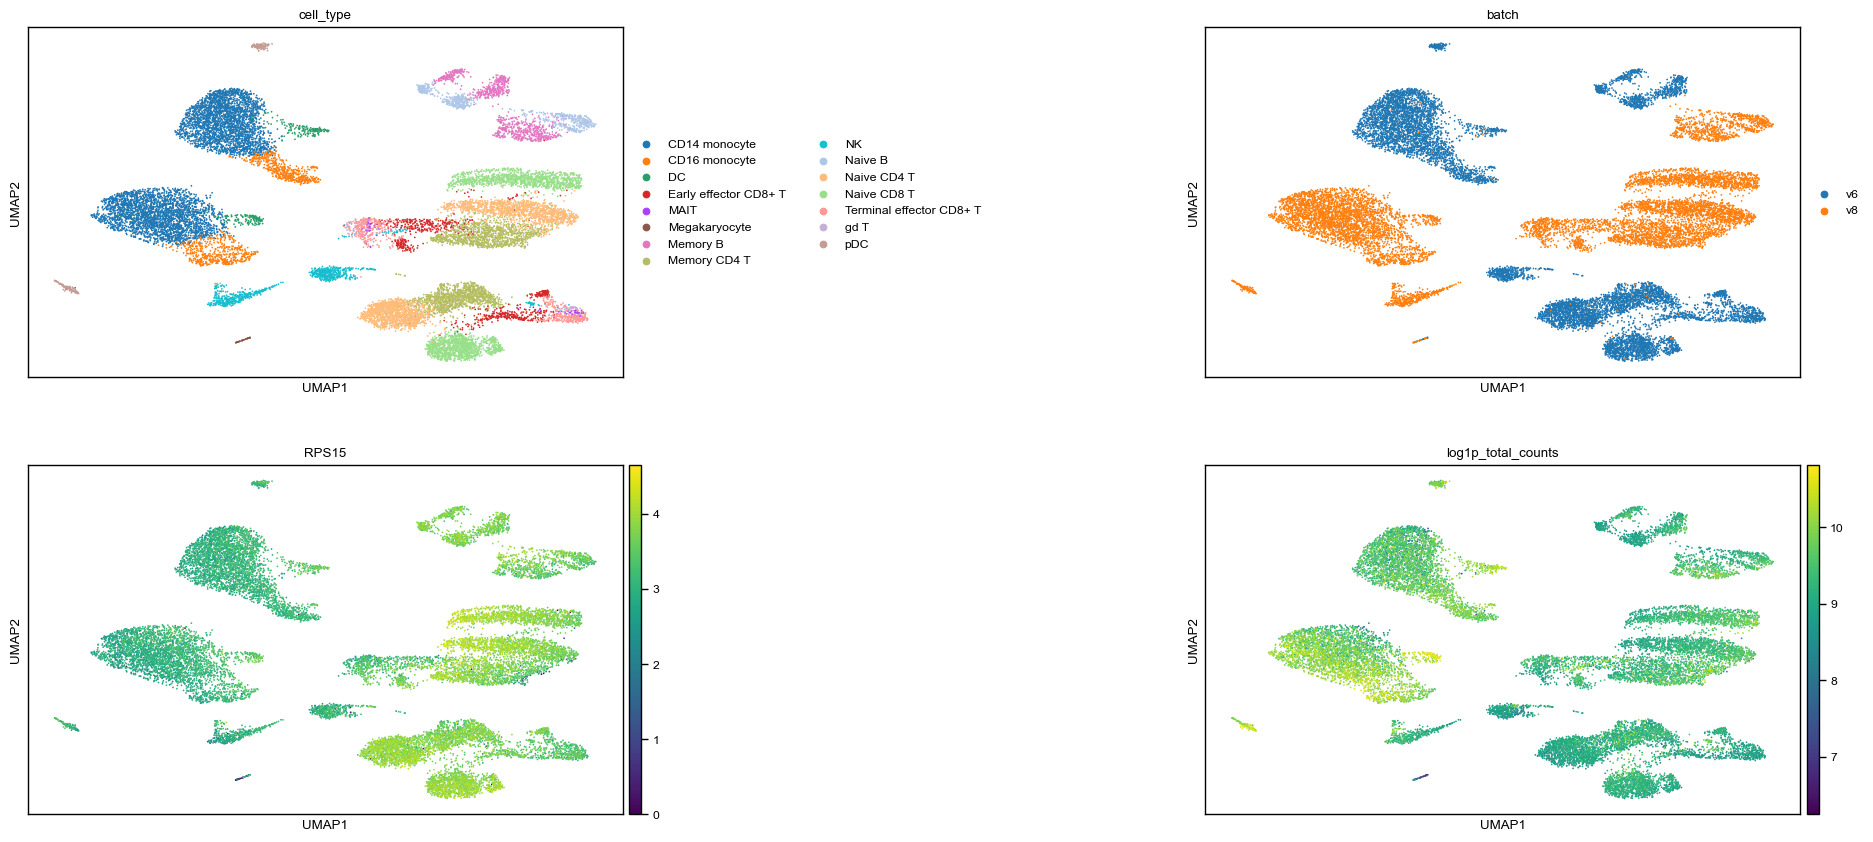

In [227]:
sc.pl.umap(adata, color=['cell_type','batch', 'RPS15', 'log1p_total_counts'], ncols=2, wspace=0.8)